In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

drive_folder = "/content/drive/MyDrive"
zip_path = None

for root, dirs, files in os.walk(drive_folder):
    if "IMDB Dataset.csv.zip" in files:
        zip_path = os.path.join(root, "IMDB Dataset.csv.zip")
        break

if zip_path:
    print("Dataset found!")
    print("File path:", zip_path)
else:
    print("ZIP file not found.")
    print("Check the filename and upload location in Google Drive.")

Dataset found!
File path: /content/drive/MyDrive/IMDB Dataset.csv.zip


In [3]:
import re
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
if zip_path is None:
    raise FileNotFoundError(
        "Run Step 3 and make sure the ZIP file is found."
    )

with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    if not csv_files:
        raise FileNotFoundError("No CSV file found inside the ZIP.")

    print("CSV file found inside ZIP:", csv_files[0])

    with z.open(csv_files[0]) as f:
        df = pd.read_csv(f)

print("\nDataset loaded successfully!")
print("Original dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())

CSV file found inside ZIP: IMDB Dataset.csv

Dataset loaded successfully!
Original dataset shape: (50000, 2)
Column names: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
df.columns = df.columns.str.strip().str.lower()

required_columns = {"review", "sentiment"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Expected columns {required_columns}, "
        f"but found {df.columns.tolist()}"
    )

df = df.dropna(subset=["review", "sentiment"]).copy()

df["review"] = df["review"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.lower().str.strip()

# Keep only valid sentiment labels
df = df[df["sentiment"].isin(["positive", "negative"])]

positive_df = df[df["sentiment"] == "positive"]
negative_df = df[df["sentiment"] == "negative"]

if len(positive_df) < 2500 or len(negative_df) < 2500:
    raise ValueError("Dataset does not contain enough reviews per class.")

positive_df = positive_df.sample(n=2500, random_state=SEED)
negative_df = negative_df.sample(n=2500, random_state=SEED)

df = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Encode sentiment: negative = 0, positive = 1
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print("Selected reviews:", len(df))
print("\nClass distribution:")
print(df["sentiment"].value_counts())

assert len(df) == 5000
assert (df["label"] == 0).sum() == 2500
assert (df["label"] == 1).sum() == 2500

print("\nDataset is ready!")

Selected reviews: 5000

Class distribution:
sentiment
positive    2500
negative    2500
Name: count, dtype: int64

Dataset is ready!


In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

# Remove empty reviews if any
df = df[df["clean_review"].str.len() > 0].reset_index(drop=True)

print("Reviews after cleaning:", len(df))
print("\nOriginal review:")
print(df.loc[0, "review"][:300])

print("\nCleaned review:")
print(df.loc[0, "clean_review"][:300])

print("\nClass distribution:")
print(df["sentiment"].value_counts())

Reviews after cleaning: 5000

Original review:
Why would this film be so good, but only gross an estimated $95,000,000 and have NO award nominations? John Travolta knows what he's doing. He knows he's Michael, a cigar smoking, womanizing, magical arch angel that came down to live with a dying lady and is now in a car with the staff of "The Natio

Cleaned review:
why would this film be so good but only gross an estimated 95 000 000 and have no award nominations john travolta knows what he's doing he knows he's michael a cigar smoking womanizing magical arch angel that came down to live with a dying lady and is now in a car with the staff of the national mirr

Class distribution:
sentiment
positive    2500
negative    2500
Name: count, dtype: int64


In [7]:
X = df["clean_review"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training reviews:", len(X_train))
print("Validation reviews:", len(X_val))
print("Testing reviews:", len(X_test))
print("Total reviews:", len(X_train) + len(X_val) + len(X_test))

Training reviews: 3500
Validation reviews: 750
Testing reviews: 750
Total reviews: 5000


In [8]:
MAX_WORDS = 10000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary from training data only
tokenizer.fit_on_texts(X_train)

# Convert words to integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

VOCAB_SIZE = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", VOCAB_SIZE)
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)

Vocabulary size: 10000
Training shape: (3500, 300)
Validation shape: (750, 300)
Testing shape: (750, 300)


In [9]:
model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 22s 318ms/step - accuracy: 0.5331 - loss: 0.6906 - val_accuracy: 0.6013 - val_loss: 0.6759
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 18s 332ms/step - accuracy: 0.6726 - loss: 0.6171 - val_accuracy: 0.7707 - val_loss: 0.4773
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 17s 302ms/step - accuracy: 0.8729 - loss: 0.3111 - val_accuracy: 0.7933 - val_loss: 0.4880
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 308ms/step - accuracy: 0.9423 - loss: 0.1663 - val_accuracy: 0.7387 - val_loss: 0.5915


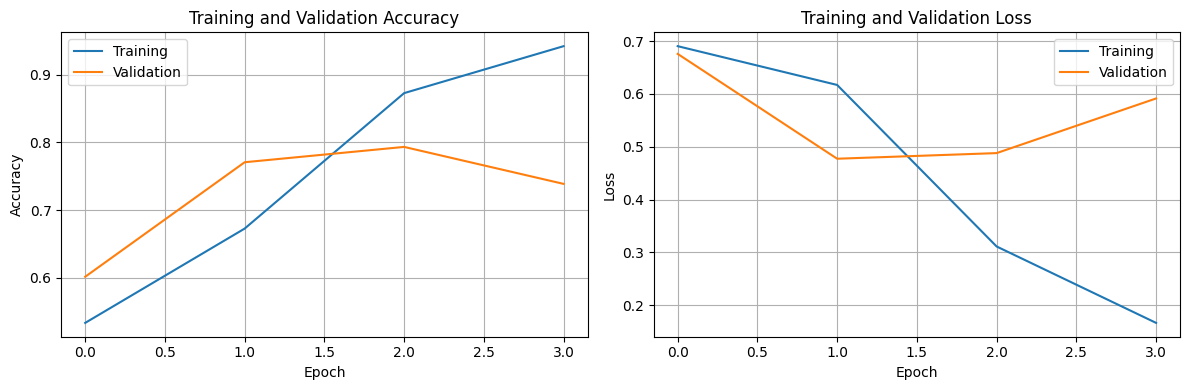

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad, y_test, verbose=0
)

y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("TEST SET RESULTS")
print("-" * 35)
print(f"Test Loss  : {test_loss:.4f}")
print(f"Accuracy   : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"F1-Score   : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))


TEST SET RESULTS
-----------------------------------
Test Loss  : 0.4711
Accuracy   : 0.7680 (76.80%)
Precision  : 0.7680
Recall     : 0.7680
F1-Score   : 0.7680

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77       375
    Positive       0.77      0.77      0.77       375

    accuracy                           0.77       750
   macro avg       0.77      0.77      0.77       750
weighted avg       0.77      0.77      0.77       750



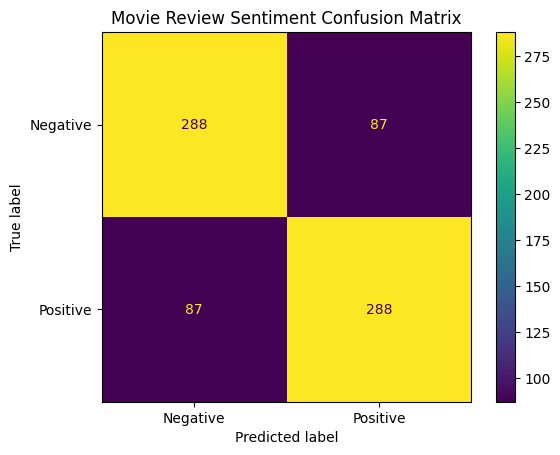

Confusion matrix:
[[288  87]
 [ 87 288]]


In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(values_format="d")
plt.title("Movie Review Sentiment Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)

In [14]:
label_names = {
    0: "Negative",
    1: "Positive"
}

# Select five training reviews
sample_texts = X_train[:5]
sample_labels = y_train[:5]
sample_padded = X_train_pad[:5]

# Predict sentiment
sample_probabilities = model.predict(
    sample_padded,
    verbose=0
).ravel()

sample_predictions = (sample_probabilities >= 0.5).astype(int)

for i in range(len(sample_texts)):
    print(f"\nREVIEW {i + 1}")
    print("-" * 50)
    print("Review:", sample_texts[i][:400])
    print("Actual sentiment:", label_names[int(sample_labels[i])])
    print("Predicted sentiment:", label_names[int(sample_predictions[i])])
    print(f"Positive probability: {sample_probabilities[i]:.4f}")

    if sample_labels[i] == sample_predictions[i]:
        print("Prediction: Correct")
    else:
        print("Prediction: Incorrect")


REVIEW 1
--------------------------------------------------
Review: wow i think the overall average rating of this film on this site is incredibly low there's really no reason to dislike this film michael is a simple but fairly original and easily enjoyable romantic comedy the plot involves a group of reporters experts going to examine the mysterious appearance of an angel john travolta in the midwest the angel proves to be less saintly and more worldly than we wo
Actual sentiment: Positive
Predicted sentiment: Positive
Positive probability: 0.9099
Prediction: Correct

REVIEW 2
--------------------------------------------------
Review: goodnight mister tom is so beautifully filmed and beautifully realised it isn't completely faithful to the book but does it have to be no not at all john thaw is mesmerising as tom oakley his transformation from gruff to caring was so well realised making it more believable than scrooge in christmas carol after inspector morse this is thaw's finest hour

In [15]:
import pickle

model_path = "/content/drive/MyDrive/movie_sentiment_lstm.keras"
tokenizer_path = "/content/drive/MyDrive/movie_tokenizer.pkl"

model.save(model_path)

with open(tokenizer_path, "wb") as f:
    pickle.dump(tokenizer, f)

print("Model saved to:", model_path)
print("Tokenizer saved to:", tokenizer_path)

Model saved to: /content/drive/MyDrive/movie_sentiment_lstm.keras
Tokenizer saved to: /content/drive/MyDrive/movie_tokenizer.pkl


In [19]:
def predict_sentiment(review):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert text into numbers using the trained tokenizer
    sequence = tokenizer.texts_to_sequences([cleaned_review])

    # Pad the sequence to match the model input length
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict sentiment
    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        print("Sentiment: POSITIVE")
    else:
        print("Sentiment: NEGATIVE")

    print(f"Positive probability: {probability:.2%}")


# Get review from the user at runtime
user_review = input("Enter a movie review: ")
predict_sentiment(user_review)

Enter a movie review: This movie was amazing, the acting was excellent and I loved every moment.
Sentiment: POSITIVE
Positive probability: 59.82%


In [20]:
def predict_sentiment(review):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert text into numbers using the trained tokenizer
    sequence = tokenizer.texts_to_sequences([cleaned_review])

    # Pad the sequence to match the model input length
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict sentiment
    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        print("Sentiment: POSITIVE")
    else:
        print("Sentiment: NEGATIVE")

    print(f"Positive probability: {probability:.2%}")


# Get review from the user at runtime
user_review = input("Enter a movie review: ")
predict_sentiment(user_review)

Enter a movie review: This movie was terrible, the acting was boring and I hated every moment.
Sentiment: NEGATIVE
Positive probability: 12.30%
